<a href="https://colab.research.google.com/github/zouhiraghenaim/Supervised-Learning-Algorithms/blob/main/TP5_Decision_Tree/TP5_01__Simple%20Decision%20tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://google.com)](https://google.com)


# **Simple Decision Tree**

**Setup & Data Preparation**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Q1.1: Create a Python DataFrame
data = {
    'Observation': ['A', 'B', 'C', 'D', 'E', 'F'],
    'X1': [1, 2, 1, 4, 5, 4],
    'X2': [1, 1, 2, 4, 4, 5],
    'Class': [-1, -1, -1, 1, 1, 1]
}
df = pd.DataFrame(data)

# Q1.2: Separate input features (X) from target (y)
X = df[['X1', 'X2']]
y = df['Class']

# **Question 1: Root Node Evaluation**
Requirement: Write a function to calculate Gini impurity and evaluate the root node.

In [11]:
# Q1.3: Function to calculate Gini impurity
def calculate_gini(y_target):
    if len(y_target) == 0:
        return 0.0
    probs = y_target.value_counts(normalize=True)
    return 1 - (probs ** 2).sum()

# Q1.4: Calculate root Gini impurity and interpret
root_gini = calculate_gini(y)
print(f" Root Node Gini Impurity: {root_gini:.4f}")
# Output: 0.5000 (Maximum impurity; 3 negatives, 3 positives)

 Root Node Gini Impurity: 0.5000


# **Question 2: Candidate Threshold Generation**
Requirement: Extract unique values and calculate midpoints for both features.

In [12]:
# Q2.2: General function to generate midpoints automatically
def generate_thresholds(series):
    unique_vals = sorted(series.unique())
    return [(unique_vals[i] + unique_vals[i+1]) / 2 for i in range(len(unique_vals)-1)]

# Q2.3: Display all candidate thresholds
for col in X.columns:
    print(f" Candidate Thresholds for {col}: {generate_thresholds(df[col])}")
# Output for X1 & X2: [1.5, 3.0, 4.5]

 Candidate Thresholds for X1: [np.float64(1.5), np.float64(3.0), np.float64(4.5)]
 Candidate Thresholds for X2: [np.float64(1.5), np.float64(3.0), np.float64(4.5)]


# **Questions 3 & 4: Evaluating Splits & Selecting the Optimal One**
Requirement: Evaluate specific splits and all splits to find the best one. We use a single function to handle both, eliminating duplication.

In [14]:
# General function to evaluate ANY split
def evaluate_split(df, feature, threshold, root_gini):
    left = df[df[feature] <= threshold]
    right = df[df[feature] > threshold]

    gini_left = calculate_gini(left['Class'])
    gini_right = calculate_gini(right['Class'])

    n, n_left, n_right = len(df), len(left), len(right)
    weighted_gini = (n_left / n) * gini_left + (n_right / n) * gini_right
    gini_gain = root_gini - weighted_gini

    return {
        'Feature': feature, 'Threshold': threshold,
        'Left Obs': list(left['Observation']), 'Right Obs': list(right['Observation']),
        'Gini Left': gini_left, 'Gini Right': gini_right,
        'Weighted Gini': weighted_gini, 'Gini Gain': gini_gain
    }

# Q3: Evaluate the specific condition X1 <= 1.5
q3_result = evaluate_split(df, 'X1', 1.5, root_gini)
print("\n Evaluation for X1 <= 1.5:")
print(f"Left: {q3_result['Left Obs']} | Right: {q3_result['Right Obs']}")
print(f"Weighted Gini: {q3_result['Weighted Gini']:.4f} | Gini Gain: {q3_result['Gini Gain']:.4f}")

# Q4: Evaluate ALL candidate splits and store in a DataFrame
all_results = []
for col in X.columns:
    for t in generate_thresholds(df[col]):
        all_results.append(evaluate_split(df, col, t, root_gini))

results_df = pd.DataFrame(all_results)
print("\n All Splits Evaluated:")
print(results_df[['Feature', 'Threshold', 'Left Obs', 'Right Obs', 'Weighted Gini', 'Gini Gain']].to_string(index=False))

# Q4: Identify the optimal root splitting condition (Lowest Weighted Gini)
best_split = results_df.loc[results_df['Weighted Gini'].idxmin()]
print(f"\n Optimal Split: {best_split['Feature']} <= {best_split['Threshold']} (Gini = 0.00)")


 Evaluation for X1 <= 1.5:
Left: ['A', 'C'] | Right: ['B', 'D', 'E', 'F']
Weighted Gini: 0.2500 | Gini Gain: 0.2500

 All Splits Evaluated:
Feature  Threshold        Left Obs    Right Obs  Weighted Gini  Gini Gain
     X1        1.5          [A, C] [B, D, E, F]           0.25       0.25
     X1        3.0       [A, B, C]    [D, E, F]           0.00       0.50
     X1        4.5 [A, B, C, D, F]          [E]           0.40       0.10
     X2        1.5          [A, B] [C, D, E, F]           0.25       0.25
     X2        3.0       [A, B, C]    [D, E, F]           0.00       0.50
     X2        4.5 [A, B, C, D, E]          [F]           0.40       0.10

 Optimal Split: X1 <= 3.0 (Gini = 0.00)


# **Question 5: Constructing and Interpreting the Decision Tree**
Requirement: Train the model, plot it, and predict for (X1=3, X2=3).

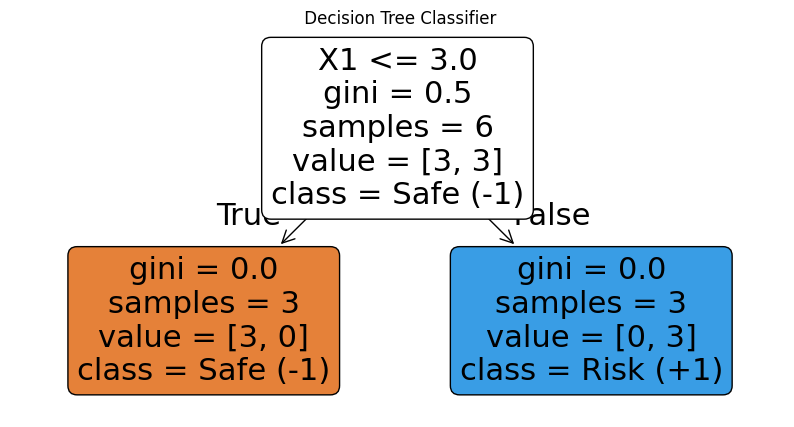

Prediction for a client with X1=3, X2=3 is: Class -1 (Safe Client)


In [15]:
# Q5.1 & Q5.2: Train the Decision Tree (max_depth=1 because one split creates pure nodes)
tree_model = DecisionTreeClassifier(criterion='gini', max_depth=1, random_state=42)
tree_model.fit(X, y)

# Q5.3: Visualize the tree
plt.figure(figsize=(10, 5))
plot_tree(tree_model, feature_names=X.columns, class_names=['Safe (-1)', 'Risk (+1)'], filled=True, rounded=True)
plt.title(" Decision Tree Classifier")
plt.show()

# Q5.6: Predict a new observation (X1=3, X2=3)
new_client = pd.DataFrame([[3, 3]], columns=X.columns)
prediction = tree_model.predict(new_client)[0]
print(f"Prediction for a client with X1=3, X2=3 is: Class {prediction} (Safe Client)")



#  **Summary & Optional Extension**

### **Optional Extension: The "Tie" Phenomenon**
**Observation:**
When evaluating all candidate splits, both **\(X_1 \le 3.0\)** and **\(X_2 \le 3.0\)** achieve a **Weighted Gini = 0.00** and a **Gini Gain = 0.50**.

*   The dataset is perfectly designed. Both features completely isolate the negative class (Clients A, B, C) from the positive class (Clients D, E, F) at the exact value of 3.
*   Because the resulting left and right nodes are 100% pure, the impurity drops to absolute zero for both features.

**How does the Algorithm resolve this?**
*   Mathematically, both features are equally perfect.
*   **In `scikit-learn`**, the `DecisionTreeClassifier` evaluates features sequentially. It will default to the feature that appears first in the feature matrix (in this case, **\(X_1\)**) as the root node.


### **Final Business Conclusion**
Regardless of which feature the algorithm chooses, the business rule remains identical:
*   **Threshold = 3** is the critical boundary.
*   \(\le 3\) (Late payments or Risk level) \(\rightarrow\) **Safe Investment (Class -1)**
*   \(> 3\) \(\rightarrow\) **High Risk / Rejected (Class +1)**

*This proves how **Decision Trees** act as highly interpretable, automated policy-makers.*